# Social Learning Preliminary Analysis

Multi-agent bandit experiments comparing individual learners against various social learning strategies (naive Thompson, naive greedy, demo oracle Thompson, demo oracle greedy).

In [1]:
%matplotlib inline

import numpy as np
import random
import sys
import os
import pandas as pd
from scipy.stats import entropy
import matplotlib.pyplot as plt
from typing import List
from pathlib import Path

sys.path.insert(0, '../src')
from utils import get_output_data_dir, write_run_yaml, write_config_yaml, finalize_run_yaml

In [2]:
class Bandit: 
    def __init__(self, payoffs: List[float]):
        self.payoffs = payoffs

    def pull(self, action: int) -> int:
        if random.random() < self.payoffs[action]:
            return 1
        return 0

    @property
    def K(self):
        return len(self.payoffs)

In [3]:
class GreedySampler():
    def __init__(self, alphas: np.ndarray, betas: np.ndarray, bandit: Bandit, T: int):
        self._alphas = alphas
        self._betas = betas
        self._bandit = bandit 
        self._T = T
        self._actions = np.zeros(T, dtype=int)
        self._rewards = np.zeros(T, dtype=int)
        self.q_values = self._alphas / (self._alphas + self._betas)

    def _sample_action(self) -> int: 
        return np.argmax(self.q_values)

    def run(self):
        for t in range(self._T):
            action = self._sample_action()
            reward = self._bandit.pull(action)
            self._actions[t] = action
            self._rewards[t] = reward

    @property
    def actions(self) -> np.ndarray:
        return self._actions

    @property
    def rewards(self) -> np.ndarray:
        return self._rewards

In [4]:
class ThompsonSampler():
    def __init__(self, alphas: np.ndarray, betas: np.ndarray, bandit: Bandit, T: int):
        self._alphas = alphas
        self._betas = betas
        self._bandit = bandit
        self._t_alphas = np.zeros((T, bandit.K), dtype=int)
        self._t_betas = np.zeros((T, bandit.K), dtype=int)
        self._T = T
        self._actions = np.zeros(T, dtype=int)
        self._rewards = np.zeros(T, dtype=int)

    def _sample_action(self) -> int:
        return np.argmax(np.random.beta(self._alphas, self._betas))

    def run(self):
        for t in range(self._T):
            action = self._sample_action()
            reward = self._bandit.pull(action)
            self._alphas[action] += reward
            self._betas[action] += 1 - reward
            self._t_alphas[t] = self._alphas
            self._t_betas[t] = self._betas
            self._actions[t] = action
            self._rewards[t] = reward

    @property
    def alphas(self) -> np.ndarray:
        return self._alphas

    @property
    def betas(self) -> np.ndarray:
        return self._betas

    @property
    def bandit(self) -> Bandit:
        return self._bandit

    @property
    def T(self) -> int:
        return self._T

    @property
    def t_alphas(self) -> np.ndarray:
        return self._t_alphas

    @property
    def t_betas(self) -> np.ndarray:
        return self._t_betas
    
    @property
    def actions(self) -> np.ndarray:
        return self._actions

    @property
    def rewards(self) -> np.ndarray:
        return self._rewards

In [5]:
class Agent():
    def __init__(self, agent_type, actions, rewards):
        self.agent_type = agent_type
        self.rewards = rewards
        self.cumulative_rewards = np.cumsum(rewards)
        self.entropy = compute_entropy(actions)

def compute_entropy(actions):
    counts = np.bincount(actions, minlength=12)
    return entropy(actions)

In [6]:
def append_to_csv(agent, T_E, T_D, T_P, trial_id, filepath):
    """Append agent data to CSV file."""
    n = len(agent.rewards)
    new_data = pd.DataFrame({
        'trial_id': np.repeat(trial_id, n),
        'agent_type': np.repeat(agent.agent_type, n),
        'T_E': np.repeat(T_E, n),
        'T_D': np.repeat(T_D, n),
        'T_P': np.repeat(T_P, n),
        'rewards': agent.rewards,
        'cumulative_rewards': agent.cumulative_rewards,
        'entropy': agent.entropy
    })  
    file_exists = os.path.isfile(filepath)
    new_data.to_csv(filepath, mode='a', header=not file_exists, index=False)

In [7]:
def generate_plot_data(input_csv, output_csv):
    """
    Pre-compute aggregated statistics for fast plotting.
    
    Reads the raw data CSV and generates a summary CSV with means and standard errors
    for each combination of agent_type, T_E, T_D, and T_P.
    
    Args:
        input_csv: Path to raw data CSV file
        output_csv: Path to output aggregated CSV file
    """
    print(f"Generating plot data from {input_csv}...")
    
    # Read raw data
    df = pd.read_csv(input_csv)
    
    # First, aggregate per trial (average across timesteps within each trial)
    df_per_trial = df.groupby(['trial_id', 'agent_type', 'T_E', 'T_D', 'T_P']).agg({
        'entropy': 'mean',
        'rewards': 'mean',
        'cumulative_rewards': 'last'  # Take final cumulative value
    }).reset_index()
    
    # Now aggregate across trials for each combination to get statistics
    grouped = df_per_trial.groupby(['agent_type', 'T_E', 'T_D', 'T_P'])
    
    # Compute mean, std, and count for each metric
    stats_list = []
    for name, group in grouped:
        agent_type, t_e, t_d, t_p = name
        
        row = {
            'agent_type': agent_type,
            'T_E': t_e,
            'T_D': t_d,
            'T_P': t_p
        }
        
        # For each metric, compute mean, std, count, and SE
        for metric in ['entropy', 'rewards', 'cumulative_rewards']:
            values = group[metric]
            mean_val = values.mean()
            std_val = values.std()
            count_val = len(values)
            # Handle case where std is NaN (single sample)
            if pd.isna(std_val) or count_val <= 1:
                se_val = 0.0
            else:
                se_val = std_val / np.sqrt(count_val)
            
            row[f'{metric}_mean'] = mean_val
            row[f'{metric}_std'] = std_val if not pd.isna(std_val) else 0.0
            row[f'{metric}_se'] = se_val
            row[f'{metric}_n'] = count_val
        
        stats_list.append(row)
    
    # Create DataFrame from list
    stats_df = pd.DataFrame(stats_list)
    
    # Sort for readability
    stats_df = stats_df.sort_values(['agent_type', 'T_E', 'T_D', 'T_P'])
    
    # Save to CSV
    stats_df.to_csv(output_csv, index=False)
    
    print(f"Plot data saved to {output_csv}")
    print(f"Reduced from {len(df)} rows to {len(stats_df)} rows")
    
    return stats_df

In [8]:
def get_agent_styling(agent_types):
    """
    Get consistent colors and markers for agent types.
    
    Args:
        agent_types: List of agent type names
        
    Returns:
        Tuple of (colors_dict, markers_dict)
    """
    color_palette = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728', '#9467bd', '#8c564b']
    colors = {
        'individual learner': '#1f77b4',  # blue
        'naive thompson social learner': '#ff7f0e',  # orange
        'naive greedy social learner': '#2ca02c',  # green
        'demo oracle thompson social learner': '#d62728',  # red
        'demo oracle greedy social learner': '#9467bd',  # purple
    }
    
    # Assign colors to any additional agent types not in the predefined map
    for i, agent_type in enumerate(agent_types):
        if agent_type not in colors:
            colors[agent_type] = color_palette[i % len(color_palette)]
    
    # Marker styles for better distinction
    markers = ['o', 's', '^', 'D', 'v', '<']
    marker_map = {agent_type: markers[i % len(markers)] for i, agent_type in enumerate(agent_types)}
    
    return colors, marker_map


def plot_results(fixed, discrete, csv_file, output_file, config):
    """
    Flexible plotting function that can visualize data in any permutation of T_E, T_D, T_P.
    
    Shows average reward for all agent types across one of 6 possible variable arrangements:
    - One variable is fixed at a specific value
    - One variable is discrete (creates separate subplots)
    - One variable is ranged (x-axis within each subplot)
    
    Args:
        fixed: Tuple of (variable_name, value) e.g., ("T_E", 128)
        discrete: String variable name for discrete subplots e.g., "T_D"
        csv_file: Path to aggregated plot data CSV
        output_file: Path to save output figure
        config: Config dict with T_E, T_D, T_P lists and sorted_payoffs
    """
    # Variable name mapping for labels
    var_display_names = {
        'T_E': 'Experience Steps',
        'T_D': 'Demonstration Steps',
        'T_P': 'Practice Steps'
    }
    
    # Infer the ranged variable (the one not fixed or discrete)
    all_vars = {'T_E', 'T_D', 'T_P'}
    fixed_var, fixed_val = fixed
    ranged_var = list(all_vars - {fixed_var, discrete})[0]
    
    # Read the data
    df = pd.read_csv(csv_file)
    
    # Get discrete values from config or data
    # T_D is special - it's a max value in config but generates 1..T_D in data
    if discrete == 'T_D' and not isinstance(config[discrete], list):
        # Get actual T_D values from the data
        discrete_values = sorted(df['T_D'].unique())
    else:
        discrete_values = config[discrete]
        if not isinstance(discrete_values, list):
            discrete_values = [discrete_values]
    
    # Get ranged values for x-axis limits
    # T_D is special - it's a max value in config but generates 1..T_D in data
    if ranged_var == 'T_D' and not isinstance(config[ranged_var], list):
        # Get actual T_D values from the data
        ranged_values = sorted(df['T_D'].unique())
    else:
        ranged_values = config[ranged_var]
        if not isinstance(ranged_values, list):
            ranged_values = [ranged_values]
    x_min = min(ranged_values)
    x_max = max(ranged_values)
    # Handle case where there's only one value
    if x_min == x_max:
        x_padding = 1  # Small fixed padding
    else:
        x_padding = (x_max - x_min) * 0.05
    
    # Get max payoff for reference line
    max_payoff = max(config['sorted_payoffs'])
    
    # Create figure with 1 row and len(discrete_values) columns
    num_cols = len(discrete_values)
    fig_width = 5 * num_cols
    fig, axes = plt.subplots(1, num_cols, figsize=(fig_width, 5))
    
    # Ensure axes is always iterable
    if num_cols == 1:
        axes = [axes]
    
    # Get unique agent types and styling
    agent_types = sorted(df['agent_type'].unique())
    colors, marker_map = get_agent_styling(agent_types)
    
    # Compute y-axis limits across all subplots for consistency
    y_min = float('inf')
    y_max = float('-inf')
    
    for discrete_val in discrete_values:
        df_filtered = df[(df[fixed_var] == fixed_val) & (df[discrete] == discrete_val)]
        if len(df_filtered) > 0:
            y_min = min(y_min, (df_filtered['rewards_mean'] - df_filtered['rewards_se']).min())
            y_max = max(y_max, (df_filtered['rewards_mean'] + df_filtered['rewards_se']).max())
    
    # Add padding to y-axis
    y_range = y_max - y_min
    y_padding = y_range * 0.05
    y_limits = (y_min - y_padding, y_max + y_padding)
    
    # Plot each discrete value in a separate subplot
    for col_idx, discrete_val in enumerate(discrete_values):
        ax = axes[col_idx]
        
        # Filter data for this fixed and discrete value
        df_filtered = df[(df[fixed_var] == fixed_val) & (df[discrete] == discrete_val)]
        
        # Plot each agent type
        for agent_type in agent_types:
            df_agent = df_filtered[df_filtered['agent_type'] == agent_type]
            
            # Sort by ranged variable for proper line plotting
            df_agent = df_agent.sort_values(ranged_var)
            
            if len(df_agent) > 0:
                # Plot with error bars
                ax.errorbar(df_agent[ranged_var], 
                           df_agent['rewards_mean'],
                           yerr=df_agent['rewards_se'],
                           label=agent_type,
                           color=colors[agent_type],
                           marker=marker_map[agent_type],
                           capsize=3,
                           capthick=1,
                           linewidth=2,
                           markersize=4,
                           alpha=0.8)
        
        # Add horizontal dashed line at max_payoff
        ax.axhline(y=max_payoff, color='black', linestyle='--', 
                  linewidth=1.5, alpha=0.7, label='Max Payoff' if col_idx == 0 else '')
        
        # Configure subplot
        ax.grid(True, alpha=0.3)
        ax.set_xlim(x_min - x_padding, x_max + x_padding)
        ax.set_ylim(y_limits)
        
        # Subplot title
        ax.set_title(f'{discrete} = {discrete_val}', fontsize=12, fontweight='bold')
        
        # X-axis label
        ax.set_xlabel(f'{ranged_var} ({var_display_names[ranged_var]})', fontsize=11)
        
        # Y-axis label (only on leftmost subplot)
        if col_idx == 0:
            ax.set_ylabel('Average Reward', fontsize=11)
        
        # Legend (only on first subplot)
        if col_idx == 0:
            ax.legend(fontsize=8, loc='best')
    
    # Overall title
    fig.suptitle(f'Average Reward | Fixed: {fixed_var}={fixed_val} | Discrete: {discrete} | Range: {ranged_var}', 
                 fontsize=14, fontweight='bold', y=1.02)
    
    plt.tight_layout()
    
    # Save the figure
    plt.savefig(output_file, dpi=300, bbox_inches='tight')
    print(f"Figure saved to {output_file}")
    plt.show()
    plt.close(fig)
    
    return fig

## Configuration

In [9]:
config = {
    'K': 12,
    'T_E': [0,2,4,8,16,32,64,128,256],
    'T_D': 20,
    'T_P': [2, 4, 8, 16, 32, 64, 128, 256],
    'n_trials': 256,
    'seed': 1234,  # Change this value to get different random results, or set to None
    'sorted_payoffs': [0.0, 0.1, 0.2, 0.3, 0.35, 0.4, 0.45, 0.5, 0.55, 0.6, 0.75, 0.8],
}

# Set random seed if provided
if config['seed'] is not None:
    random.seed(config['seed'])
    np.random.seed(config['seed'])
    print(f"Random seed set to {config['seed']}")

Random seed set to 1234


## Run Analysis

In [10]:
# Setup analysis directory
analysis_dir = get_output_data_dir() / 'prelim_analysis'
for subdir in ['data', 'figures', 'metadata']:
    (analysis_dir / subdir).mkdir(parents=True, exist_ok=True)
print(f"Analysis directory: {analysis_dir}")

# Write config and run metadata
write_config_yaml(analysis_dir, config, subdir='metadata')

metadata = {
    'command': 'notebook: prelim_analysis.ipynb',
}
write_run_yaml(analysis_dir, metadata, subdir='metadata')

Analysis directory: /spark2/julio/SocialBanditsProject/output/prelim_analysis


In [11]:
def run_social_learning_analysis(run_dir, config):
    """
    Run social learning analysis experiments.
    
    Args:
        run_dir: Path to run directory
        config: Dictionary with experiment parameters (K, T_E, T_D, T_P, n_trials, seed, sorted_payoffs)
    """
    K = config['K']
    T_E = config['T_E']
    T_D = config['T_D']
    T_P = config['T_P']
    n_trials = config['n_trials']
    sorted_payoffs = config['sorted_payoffs']
    
    prior_alphas = np.ones(K)
    prior_betas = np.ones(K)
    
    data_dir = run_dir / 'data'
    figures_dir = run_dir / 'figures'
    raw_csv = data_dir / 'social_learning_analysis.csv'
    plot_csv = data_dir / 'social_learning_analysis_plot_data.csv'

    data_dir.mkdir(parents=True, exist_ok=True)
    figures_dir.mkdir(parents=True, exist_ok=True)
    
    print(f"Starting social learning analysis...")
    print(f"Parameters: K={K}, T_E={T_E}, T_D={T_D}, T_P={T_P}, n_trials={n_trials}")
    print(f"Output directory: {run_dir}")
    
    for i in range(n_trials):
        if (i + 1) % 50 == 0:
            print(f"  Trial {i + 1}/{n_trials}")
        payoffs = random.sample(sorted_payoffs, K)
        bandit = Bandit(payoffs)
        for t_e in T_E:
            demonstrator = ThompsonSampler(prior_alphas.copy(), prior_betas.copy(), bandit, t_e + T_D + max(T_P))
            demonstrator.run()
            for t_d in range(1, T_D + 1):
                for t_p in T_P:
                    # Individual learner
                    individual_learner_agent = Agent(
                        agent_type='individual learner',
                        actions=demonstrator.actions[t_d:t_d+t_p],
                        rewards=demonstrator.rewards[t_d:t_d+t_p]
                    )
                    append_to_csv(
                        agent=individual_learner_agent,
                        T_E=t_e, T_D=t_d, T_P=t_p,
                        trial_id=i,
                        filepath=raw_csv
                    )

                    # Naive thompson social learner
                    if t_e == 0:
                        naive_prior_alphas = demonstrator.t_alphas[t_d - 1, :].copy()
                        naive_prior_betas = demonstrator.t_betas[t_d - 1, :].copy()
                    else:
                        naive_prior_alphas = demonstrator.t_alphas[t_e + t_d - 1, :] - demonstrator.t_alphas[t_e - 1, :] + prior_alphas
                        naive_prior_betas = demonstrator.t_betas[t_e + t_d - 1, :] - demonstrator.t_betas[t_e - 1, :] + prior_betas
                    
                    naive_thompson_social_learner = ThompsonSampler(
                        naive_prior_alphas.copy(),
                        naive_prior_betas.copy(),
                        bandit, t_p
                    )
                    naive_thompson_social_learner.run()
                    naive_thompson_social_learner_agent = Agent(
                        agent_type='naive thompson social learner',
                        actions=naive_thompson_social_learner.actions,
                        rewards=naive_thompson_social_learner.rewards
                    )
                    append_to_csv(
                        agent=naive_thompson_social_learner_agent,
                        T_E=t_e, T_D=t_d, T_P=t_p,
                        trial_id=i,
                        filepath=raw_csv
                    )

                    # Naive greedy social learner
                    naive_greedy_social_learner = GreedySampler(
                        naive_prior_alphas.copy(),
                        naive_prior_betas.copy(),
                        bandit, t_p
                    )
                    naive_greedy_social_learner.run()
                    naive_greedy_social_learner_agent = Agent(
                        agent_type='naive greedy social learner',
                        actions=naive_greedy_social_learner.actions,
                        rewards=naive_greedy_social_learner.rewards
                    )
                    append_to_csv(
                        agent=naive_greedy_social_learner_agent,
                        T_E=t_e, T_D=t_d, T_P=t_p,
                        trial_id=i,
                        filepath=raw_csv
                    )

                    # Demo oracle thompson social learner
                    demo_oracle_thompson_social_learner_agent = Agent(
                        agent_type='demo oracle thompson social learner',
                        actions=demonstrator.actions[t_e + t_d - 1 : t_e + t_d - 1 + t_p + 1],
                        rewards=demonstrator.rewards[t_e + t_d - 1 : t_e + t_d - 1 + t_p + 1]
                    )
                    append_to_csv(
                        agent=demo_oracle_thompson_social_learner_agent,
                        T_E=t_e, T_D=t_d, T_P=t_p,
                        trial_id=i,
                        filepath=raw_csv
                    )

                    # Demo oracle greedy social learner
                    demo_oracle_prior_alphas = demonstrator.t_alphas[t_e + t_d - 1, :]
                    demo_oracle_prior_betas = demonstrator.t_betas[t_e + t_d - 1, :]
                    demo_oracle_greedy_social_learner = GreedySampler(
                        demo_oracle_prior_alphas.copy(),
                        demo_oracle_prior_betas.copy(),
                        bandit, t_p
                    )
                    demo_oracle_greedy_social_learner.run()
                    demo_oracle_greedy_social_learner_agent = Agent(
                        agent_type='demo oracle greedy social learner',
                        actions=demo_oracle_greedy_social_learner.actions,
                        rewards=demo_oracle_greedy_social_learner.rewards
                    )
                    append_to_csv(
                        agent=demo_oracle_greedy_social_learner_agent,
                        T_E=t_e, T_D=t_d, T_P=t_p,
                        trial_id=i,
                        filepath=raw_csv
                    )

    print(f"Completed {n_trials} trials")
    
    # Generate aggregated plot data
    print("\nGenerating aggregated statistics...")
    generate_plot_data(input_csv=raw_csv, output_csv=plot_csv)
    
    # Generate plots - all 6 permutations
    print("\nGenerating plots...")
    
    def get_fixed_value(var_name):
        if var_name == 'T_E':
            return T_E[-1] if isinstance(T_E, list) else T_E
        elif var_name == 'T_D':
            return T_D
        elif var_name == 'T_P':
            return T_P[-1] if isinstance(T_P, list) else T_P
    
    permutations = [
        ('T_E', 'T_D', 'te_fixed_td_discrete_tp_range'),
        ('T_E', 'T_P', 'te_fixed_tp_discrete_td_range'),
        ('T_D', 'T_E', 'td_fixed_te_discrete_tp_range'),
        ('T_D', 'T_P', 'td_fixed_tp_discrete_te_range'),
        ('T_P', 'T_E', 'tp_fixed_te_discrete_td_range'),
        ('T_P', 'T_D', 'tp_fixed_td_discrete_te_range'),
    ]
    
    generated_plots = []
    for fixed_var, discrete_var, filename_suffix in permutations:
        fixed_val = get_fixed_value(fixed_var)
        output_file = figures_dir / f'{filename_suffix}_{fixed_var}{fixed_val}.png'
        
        print(f"  Generating: Fixed {fixed_var}={fixed_val}, Discrete {discrete_var}")
        
        plot_results(
            fixed=(fixed_var, fixed_val),
            discrete=discrete_var,
            csv_file=plot_csv,
            output_file=output_file,
            config=config
        )
        generated_plots.append(output_file)
    
    print(f"\nAnalysis complete!")
    print(f"Raw data: {raw_csv}")
    print(f"Aggregated data: {plot_csv}")
    print(f"Generated {len(generated_plots)} plots:")
    for plot_file in generated_plots:
        print(f"  - {plot_file}")

Starting social learning analysis...
Parameters: K=12, T_E=[0, 2, 4, 8, 16, 32, 64, 128, 256], T_D=20, T_P=[2, 4, 8, 16, 32, 64, 128, 256], n_trials=256
Output directory: /spark2/julio/SocialBanditsProject/output/prelim_analysis
  Trial 50/256
  Trial 100/256
  Trial 150/256
  Trial 200/256
  Trial 250/256
Completed 256 trials

Generating aggregated statistics...
Generating plot data from /spark2/julio/SocialBanditsProject/output/prelim_analysis/data/social_learning_analysis.csv...
Plot data saved to /spark2/julio/SocialBanditsProject/output/prelim_analysis/data/social_learning_analysis_plot_data.csv
Reduced from 117872640 rows to 7200 rows

Generating plots...
  Generating: Fixed T_E=256, Discrete T_D
Figure saved to /spark2/julio/SocialBanditsProject/output/prelim_analysis/figures/te_fixed_td_discrete_tp_range_T_E256.png


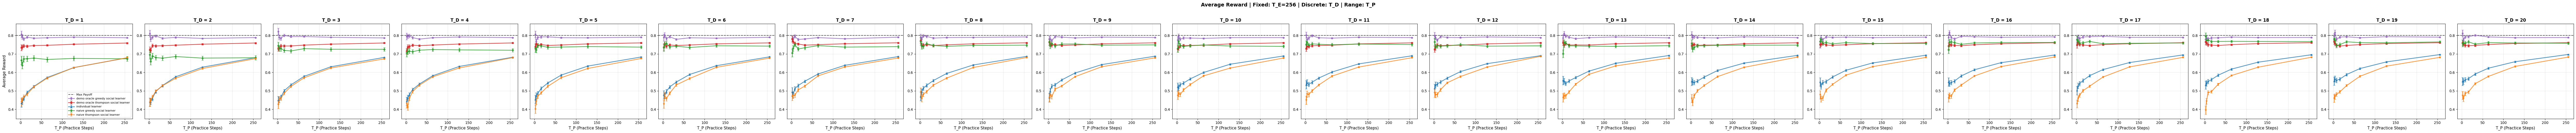

  Generating: Fixed T_E=256, Discrete T_P
Figure saved to /spark2/julio/SocialBanditsProject/output/prelim_analysis/figures/te_fixed_tp_discrete_td_range_T_E256.png


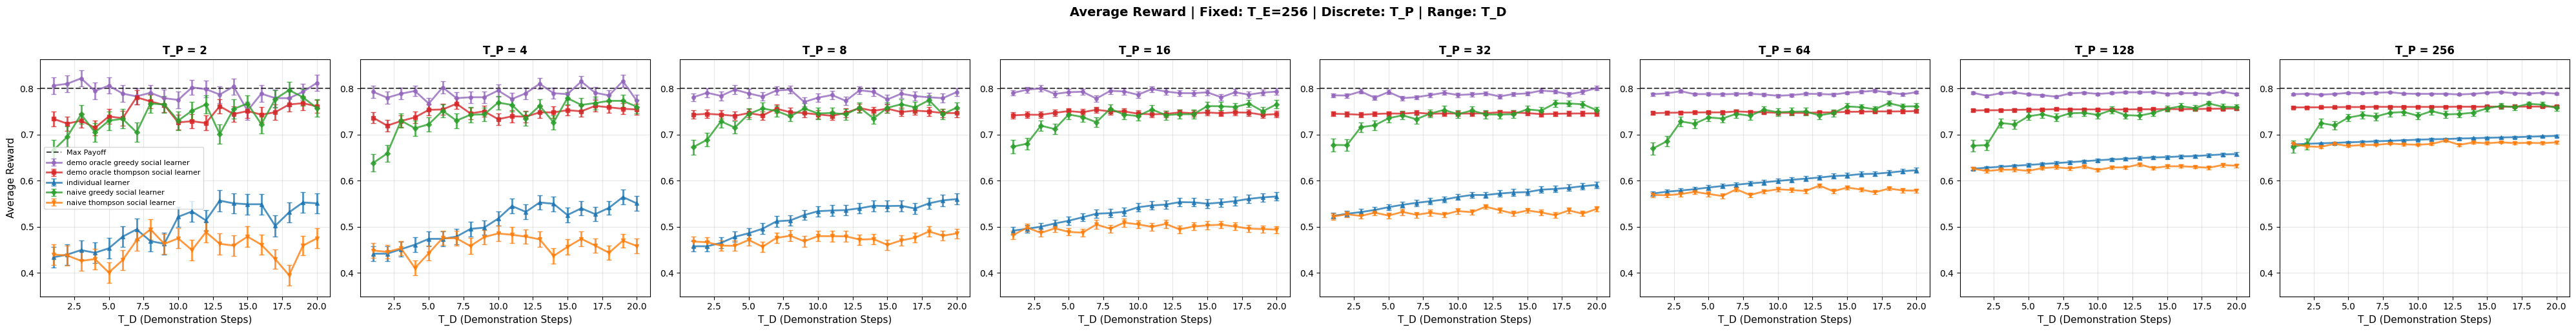

  Generating: Fixed T_D=20, Discrete T_E
Figure saved to /spark2/julio/SocialBanditsProject/output/prelim_analysis/figures/td_fixed_te_discrete_tp_range_T_D20.png


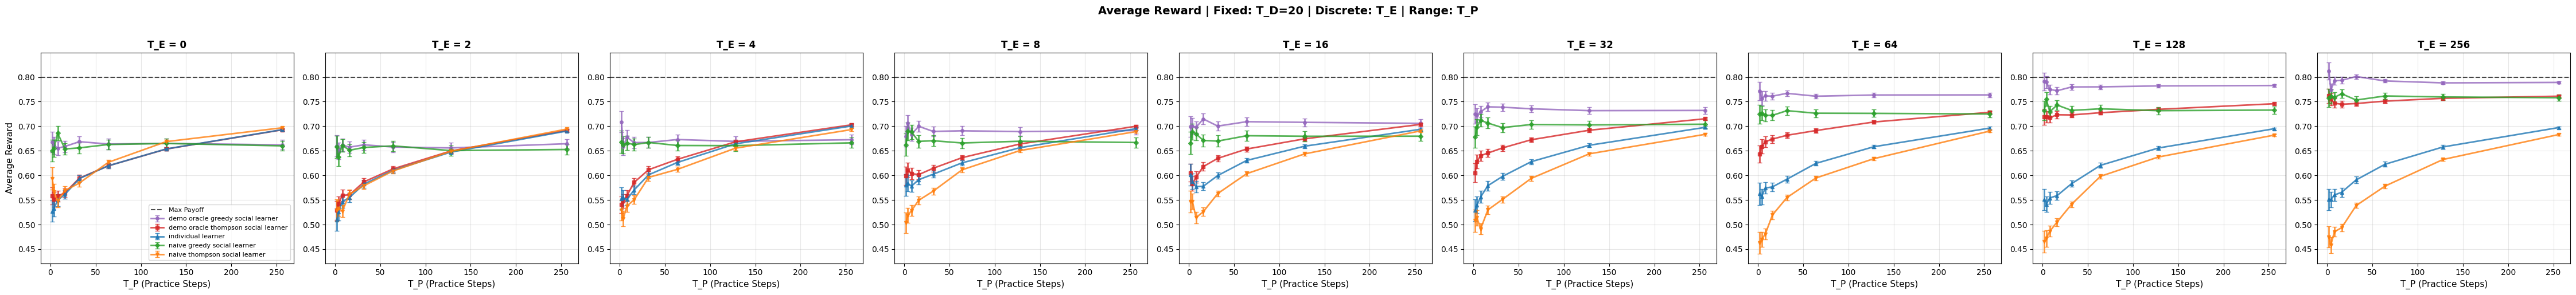

  Generating: Fixed T_D=20, Discrete T_P
Figure saved to /spark2/julio/SocialBanditsProject/output/prelim_analysis/figures/td_fixed_tp_discrete_te_range_T_D20.png


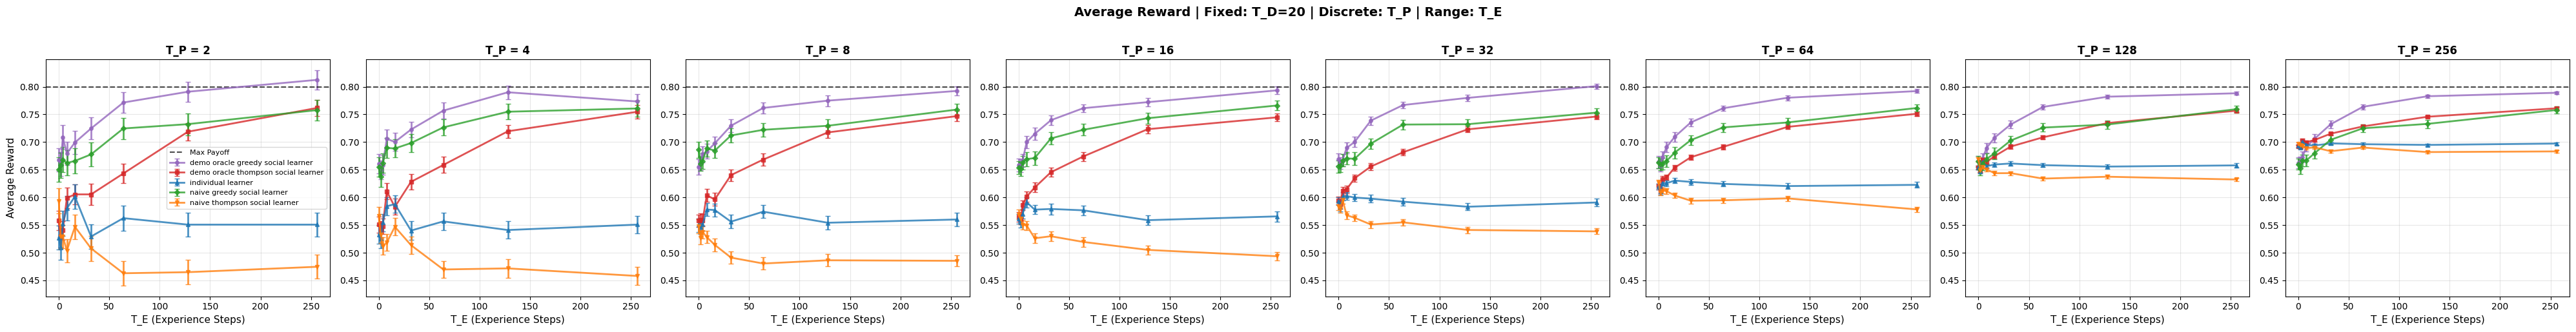

  Generating: Fixed T_P=256, Discrete T_E
Figure saved to /spark2/julio/SocialBanditsProject/output/prelim_analysis/figures/tp_fixed_te_discrete_td_range_T_P256.png


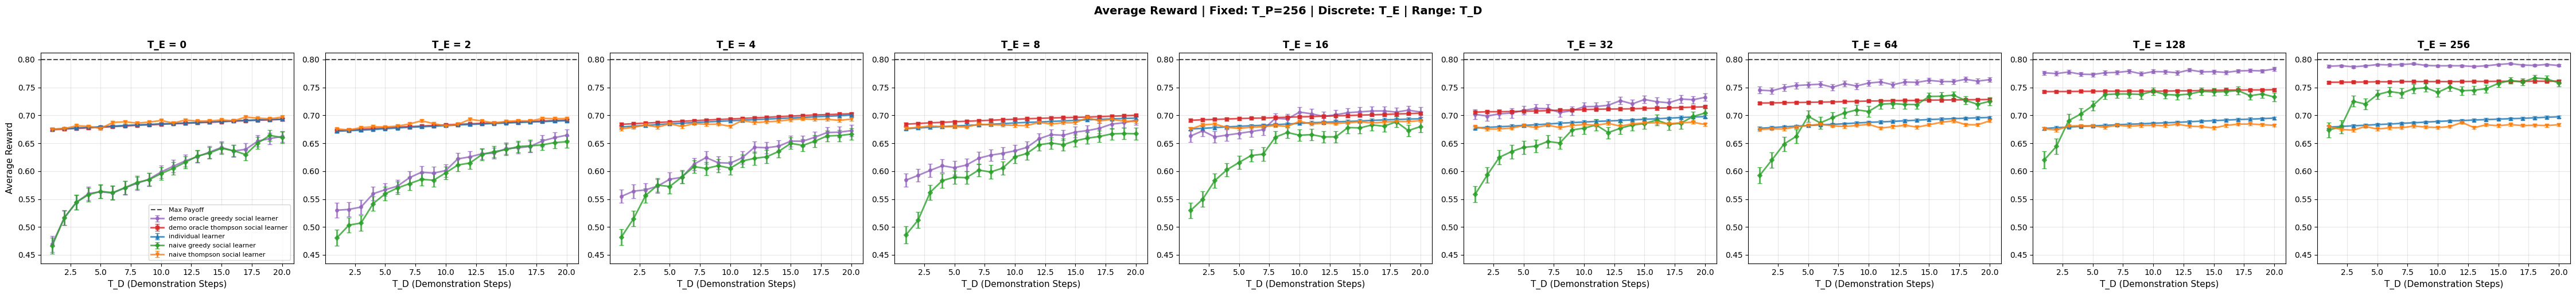

  Generating: Fixed T_P=256, Discrete T_D
Figure saved to /spark2/julio/SocialBanditsProject/output/prelim_analysis/figures/tp_fixed_td_discrete_te_range_T_P256.png


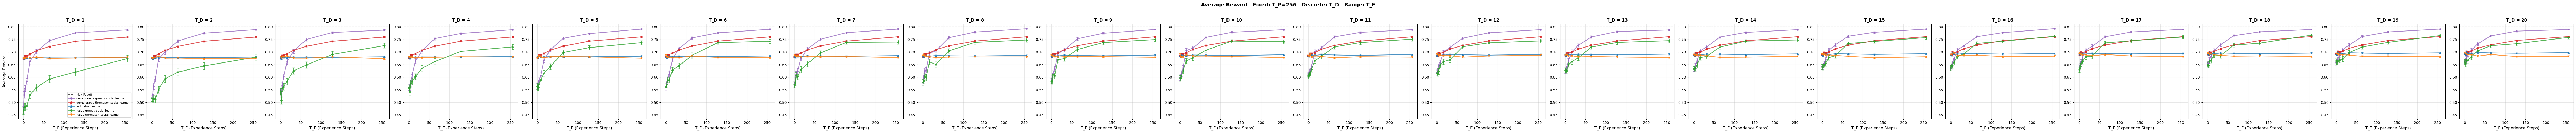


Analysis complete!
Raw data: /spark2/julio/SocialBanditsProject/output/prelim_analysis/data/social_learning_analysis.csv
Aggregated data: /spark2/julio/SocialBanditsProject/output/prelim_analysis/data/social_learning_analysis_plot_data.csv
Generated 6 plots:
  - /spark2/julio/SocialBanditsProject/output/prelim_analysis/figures/te_fixed_td_discrete_tp_range_T_E256.png
  - /spark2/julio/SocialBanditsProject/output/prelim_analysis/figures/te_fixed_tp_discrete_td_range_T_E256.png
  - /spark2/julio/SocialBanditsProject/output/prelim_analysis/figures/td_fixed_te_discrete_tp_range_T_D20.png
  - /spark2/julio/SocialBanditsProject/output/prelim_analysis/figures/td_fixed_tp_discrete_te_range_T_D20.png
  - /spark2/julio/SocialBanditsProject/output/prelim_analysis/figures/tp_fixed_te_discrete_td_range_T_P256.png
  - /spark2/julio/SocialBanditsProject/output/prelim_analysis/figures/tp_fixed_td_discrete_te_range_T_P256.png


In [12]:
run_social_learning_analysis(analysis_dir, config)